# 06 Clustering (stretch goal): ถ้าไม่บอกป้ายเลย ข้อความจะจับกลุ่มตามราศีหรือตามเว็บ

**เจ้าของ:** Member 3 · **ข้อมูล:** `data/processed/horoscopes.csv`

**คำถาม:** ให้ K-means จัดกลุ่มคำทำนาย**โดยไม่รู้ว่าข้อความไหนเป็นราศีอะไรหรือมาจากเว็บไหน** (unsupervised)
แล้วดูว่ากลุ่มที่ได้ตรงกับ**ราศี**หรือตรงกับ**เว็บ**

**วิธี (L9 Clustering):**
- TF-IDF ของคำ (`clean_text` + `tokenize`, `min_df=2`) แต่ละข้อความเป็นเวกเตอร์ยาว 1 หน่วย (ระยะ Euclidean จึงสัมพันธ์กับ cosine)
- K-means: เลือก k ด้วย **elbow (WCSS)** และ **silhouette score** และลอง **k = 12** (จำนวนราศี) กับ **k = 4** (จำนวนเว็บ) ด้วย
- วัดความตรงกันด้วย **Adjusted Rand Index (ARI)**: 1 = กลุ่มตรงกับป้ายทั้งหมด, 0 = ไม่ดีกว่าการสุ่ม
- ภาพ: ลดมิติด้วย **PCA** เหลือ 2 มิติ แล้ววาดแบบ **small multiples** (เน้นทีละราศีหรือทีละเว็บ)
  เพราะ 12 สีในกราฟเดียวแยกด้วยตาไม่ได้

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import adjusted_rand_score, silhouette_score

warnings.filterwarnings("ignore")
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.thai_text import THAI_FONT, ZODIAC_TH, clean_text, tokenize

FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
font_manager.fontManager.addfont(THAI_FONT)
THAI_FONT_NAME = font_manager.FontProperties(fname=THAI_FONT).get_name()
plt.rcParams.update({
    "font.family": THAI_FONT_NAME, "font.size": 11,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "normal",
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "savefig.dpi": 200, "savefig.bbox": "tight",
})
SITES = ["marumura", "sanook", "thairath", "kapook"]
SITE_COLORS = {"marumura": "#2a78d6", "sanook": "#eb6834", "thairath": "#1baf7a", "kapook": "#eda100"}
SIGNS = ["Aries", "Taurus", "Gemini", "Cancer", "Leo", "Virgo", "Libra", "Scorpio",
         "Sagittarius", "Capricorn", "Aquarius", "Pisces"]
SIGN_TH = {en: th for th, en in ZODIAC_TH.items()}
BLUE_RAMP = LinearSegmentedColormap.from_list(
    "blue_ramp", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

## 1) TF-IDF

In [2]:
df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "horoscopes.csv")
df["tokens"] = df["text"].apply(lambda t: tokenize(clean_text(t)))
tfidf = TfidfVectorizer(analyzer=lambda words: words, min_df=2)   # texts are already tokenized
X = tfidf.fit_transform(df["tokens"])                              # each row has length 1 (L2 norm)
print("TF-IDF matrix:", X.shape)

TF-IDF matrix: (1233, 3848)


## 2) เลือก k: elbow (WCSS) และ silhouette

- **WCSS** (within-cluster sum of squares) = ผลรวมระยะของแต่ละจุดถึงจุดกลางของกลุ่ม ยิ่ง k มาก WCSS ยิ่งลด ให้หา "ข้อศอก" ที่ลดช้าลง
- **Silhouette** (−1 ถึง 1) = ข้อความอยู่ใกล้กลุ่มตัวเองมากกว่ากลุ่มอื่นแค่ไหน ยิ่งสูงยิ่งดี (ใช้ระยะ cosine)

In [3]:
rows = []
for k in range(2, 16):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    rows.append({"k": k, "WCSS": km.inertia_, "silhouette": silhouette_score(X, km.labels_, metric="cosine"),
                 "ARI เว็บ": adjusted_rand_score(df["source"], km.labels_),
                 "ARI ราศี": adjusted_rand_score(df["zodiac"], km.labels_)})
k_table = pd.DataFrame(rows).set_index("k")
K_BEST = int(k_table["silhouette"].idxmax())
print("k with the highest silhouette:", K_BEST)
k_table.round(3)

k with the highest silhouette: 4


,WCSS,silhouette,ARI เว็บ,ARI ราศี
k,,,,
2,1093.482,0.076,0.334,-0.001
3,1076.551,0.084,0.717,-0.002
4,1062.412,0.094,0.998,-0.004
5,1053.739,0.044,0.931,0.010
6,1046.311,0.043,0.847,0.015
7,1044.233,0.044,0.824,0.014
8,1037.274,0.033,0.748,0.019
9,1034.562,0.029,0.683,0.019
10,1027.274,0.038,0.696,0.020


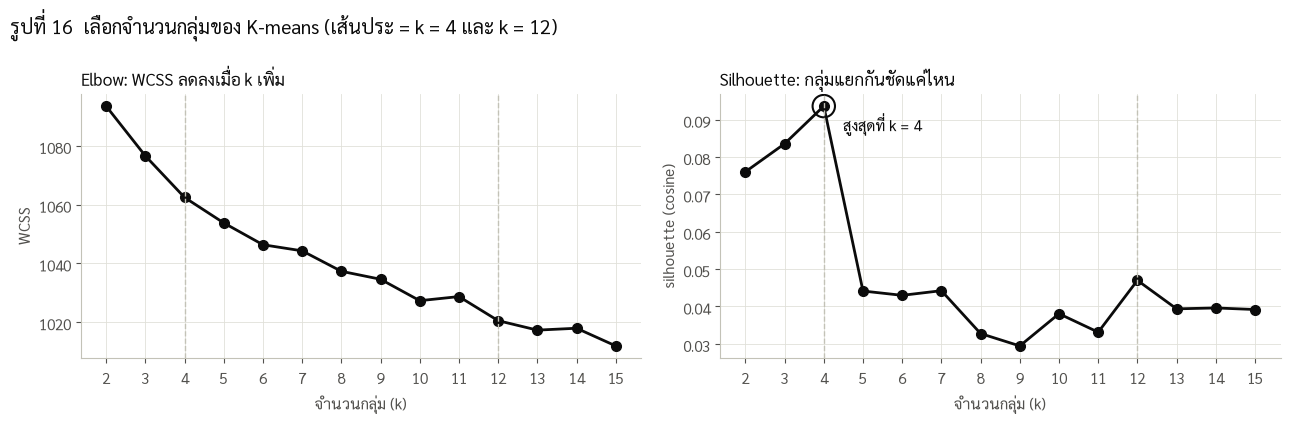

In [4]:
# Figure 16: elbow (WCSS) and silhouette
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.3))
ax1.plot(k_table.index, k_table["WCSS"], color="#0b0b0b", marker="o", linewidth=2, markersize=7)
ax1.set_xlabel("จำนวนกลุ่ม (k)"); ax1.set_ylabel("WCSS")
ax1.set_title("Elbow: WCSS ลดลงเมื่อ k เพิ่ม", loc="left")
ax2.plot(k_table.index, k_table["silhouette"], color="#0b0b0b", marker="o", linewidth=2, markersize=7)
ax2.scatter([K_BEST], [k_table.loc[K_BEST, "silhouette"]], s=260, facecolors="none", edgecolors="#0b0b0b", linewidths=1.5)
ax2.annotate(f"สูงสุดที่ k = {K_BEST}", (K_BEST, k_table.loc[K_BEST, "silhouette"]), xytext=(14, -18),
             textcoords="offset points", fontsize=11)
ax2.set_xlabel("จำนวนกลุ่ม (k)"); ax2.set_ylabel("silhouette (cosine)")
ax2.set_title("Silhouette: กลุ่มแยกกันชัดแค่ไหน", loc="left")
for ax in (ax1, ax2):
    ax.set_xticks(k_table.index)
    for k, label in [(4, "k = 4 (จำนวนเว็บ)"), (12, "k = 12 (จำนวนราศี)")]:
        ax.axvline(k, color="#c3c2b7", linestyle="--", linewidth=1)
fig.suptitle("รูปที่ 16  เลือกจำนวนกลุ่มของ K-means (เส้นประ = k = 4 และ k = 12)", x=0.01, ha="left", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_elbow_silhouette.png")
plt.show()

**จากตารางและรูปที่ 16 พบว่า**
- **Elbow (ซ้าย):** WCSS ลดลงเร็วจาก k = 2 ถึง 4 แล้วค่อยๆ ลดช้าลง "ข้อศอก" อยู่แถว **k = 4** แต่ไม่คมนัก
- **Silhouette (ขวา):** สูงสุดชัดเจนที่ **k = 4** (0.094) แล้ว**ตกลงครึ่งหนึ่งทันที**ที่ k = 5 (0.044)
  ค่า silhouette โดยรวมต่ำ เพราะข้อความยาวและใช้คำต่างกันมาก แต่จุดสูงสุดชัดเจน
- ตารางเดียวกันแสดง ARI ของทุก k: **ARI กับเว็บสูงสุด 0.998 ที่ k = 4** ส่วน **ARI กับราศีไม่เกิน 0.035 เลยสักค่า**

**ความหมาย:** K-means ไม่รู้เลยว่ามีกี่เว็บหรือกี่ราศี แต่จำนวนกลุ่มที่ดีที่สุดที่เลือกเองคือ **4 = จำนวนเว็บพอดี** ไม่ใช่ 12 = จำนวนราศี

## 3) กลุ่มที่ได้ตรงกับเว็บหรือราศี (ARI)

In [5]:
models = {k: KMeans(n_clusters=k, n_init=10, random_state=42).fit(X) for k in sorted({4, 12, K_BEST})}
ari_rows = []
for k, km in models.items():
    ari_rows.append({"k": k, "ARI กับเว็บ": adjusted_rand_score(df["source"], km.labels_),
                     "ARI กับราศี": adjusted_rand_score(df["zodiac"], km.labels_)})
# Inside each site (writer fixed): k = 12 clusters vs the 12 signs
for site in SITES:
    idx = np.where(df["source"] == site)[0]
    km = KMeans(n_clusters=12, n_init=10, random_state=42).fit(X[idx])
    ari_rows.append({"k": f"12 (เฉพาะ {site})", "ARI กับเว็บ": np.nan,
                     "ARI กับราศี": adjusted_rand_score(df["zodiac"].iloc[idx], km.labels_)})
ari_table = pd.DataFrame(ari_rows).set_index("k")
ari_table.round(3)

,ARI กับเว็บ,ARI กับราศี
k,,
4,0.998,-0.004
12,0.617,0.028
12 (เฉพาะ marumura),NaN,0.008
12 (เฉพาะ sanook),NaN,0.665
12 (เฉพาะ thairath),NaN,0.003
12 (เฉพาะ kapook),NaN,0.006


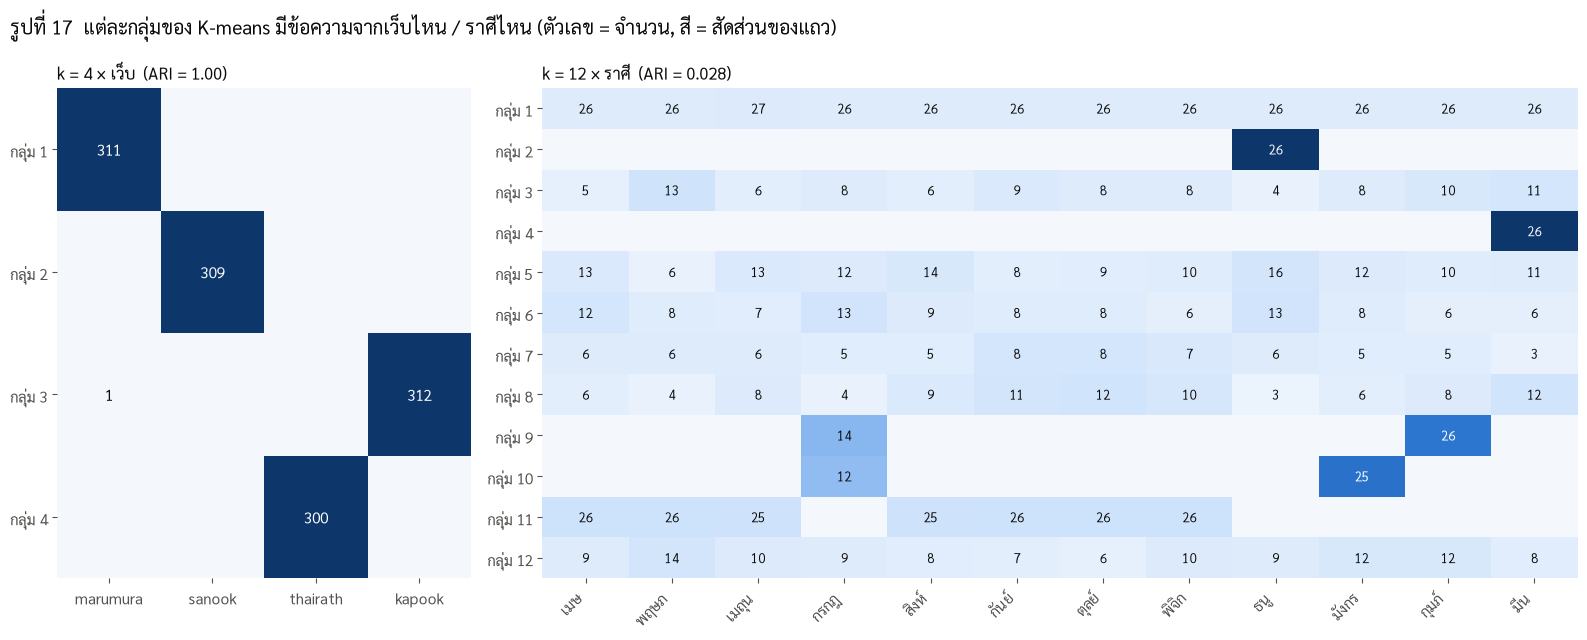

source,marumura,sanook,thairath,kapook,signs in cluster
กลุ่ม,,,,,
1,1,0,0,312,12
2,0,26,0,0,1
3,0,0,96,0,12
4,0,26,0,0,1
5,1,0,133,0,12
6,104,0,0,0,12
7,0,0,70,0,12
8,92,0,1,0,12
9,0,40,0,0,2


In [6]:
# Figure 17: cross-tabs. Left: k = 4 clusters x site. Right: k = 12 clusters x sign
def crosstab_heatmap(ax, labels, truth, order, tick_labels, title):
    table = pd.crosstab(labels, truth).reindex(columns=order, fill_value=0)
    share = table.div(table.sum(axis=1), axis=0)
    ax.imshow(share.values, cmap=BLUE_RAMP, vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(order)), tick_labels, rotation=45 if len(order) > 4 else 0, ha="right" if len(order) > 4 else "center")
    ax.set_yticks(range(len(table)), [f"กลุ่ม {c + 1}" for c in table.index])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            n = table.values[i, j]
            if n:
                ax.text(j, i, n, ha="center", va="center", fontsize=9 if len(order) > 4 else 11,
                        color="white" if share.values[i, j] > 0.55 else "#0b0b0b")
    ax.set_title(title, loc="left")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [4, 10]})
crosstab_heatmap(ax1, models[4].labels_, df["source"], SITES, SITES,
                 f"k = 4 × เว็บ  (ARI = {ari_table.loc[4, 'ARI กับเว็บ']:.2f})")
crosstab_heatmap(ax2, models[12].labels_, df["zodiac"], SIGNS, [SIGN_TH[z] for z in SIGNS],
                 f"k = 12 × ราศี  (ARI = {ari_table.loc[12, 'ARI กับราศี']:.3f})")
fig.suptitle("รูปที่ 17  แต่ละกลุ่มของ K-means มีข้อความจากเว็บไหน / ราศีไหน (ตัวเลข = จำนวน, สี = สัดส่วนของแถว)",
             x=0.01, ha="left", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_crosstab_clusters.png")
plt.show()

# Which site does each k = 12 cluster come from?
k12 = pd.crosstab(models[12].labels_ + 1, df["source"]).reindex(columns=SITES, fill_value=0)
k12["signs in cluster"] = pd.crosstab(models[12].labels_ + 1, df["zodiac"]).gt(0).sum(axis=1)
k12.index.name = "กลุ่ม"
k12

**จากรูปที่ 17 และตารางด้านบน พบว่า**
- **k = 4 (ซ้าย):** ทั้ง 4 กลุ่ม**คือ 4 เว็บ** ผิดแค่ 1 ข้อความจาก 1,233 (ARI = 0.998)
- **k = 12 (ขวา):** ถ้าบังคับให้แบ่ง 12 กลุ่มเท่าจำนวนราศี **ทุกกลุ่มยังมาจากเว็บเดียว** (ตาราง: kapook 1 กลุ่ม, marumura 3, thairath 3, sanook 5) โดยไม่ได้แบ่งตามราศี
  - กลุ่มของ marumura, thairath และ kapook **มีครบทั้ง 12 ราศี** ปนกันพอๆ กัน เช่น กลุ่ม 1 มีทุกราศีราศีละ 26 ข้อความ
  - กลุ่มที่ตรงกับราศี (กลุ่ม 2 = ราศีธนู, กลุ่ม 4 = ราศีมีน, กลุ่ม 9 = ราศีกรกฎ + ราศีกุมภ์, กลุ่ม 10 = ราศีกรกฎ + ราศีมังกร) **มาจาก sanook ทั้งหมด** เพราะย่อหน้าดาวประจำราศีที่ใช้ซ้ำ (เหมือนใน 03 และ 04)
- **ภายในเว็บ (ตาราง ARI):** แบ่ง 12 กลุ่มภายใน marumura, thairath และ kapook ได้ ARI กับราศีแค่ 0.003–0.008 (≈ สุ่ม) มีแค่ sanook ที่ได้ 0.67

## 4) PCA: ข้อความกระจายตัวอย่างไร

PCA 2 components explain 7.0% of the variance


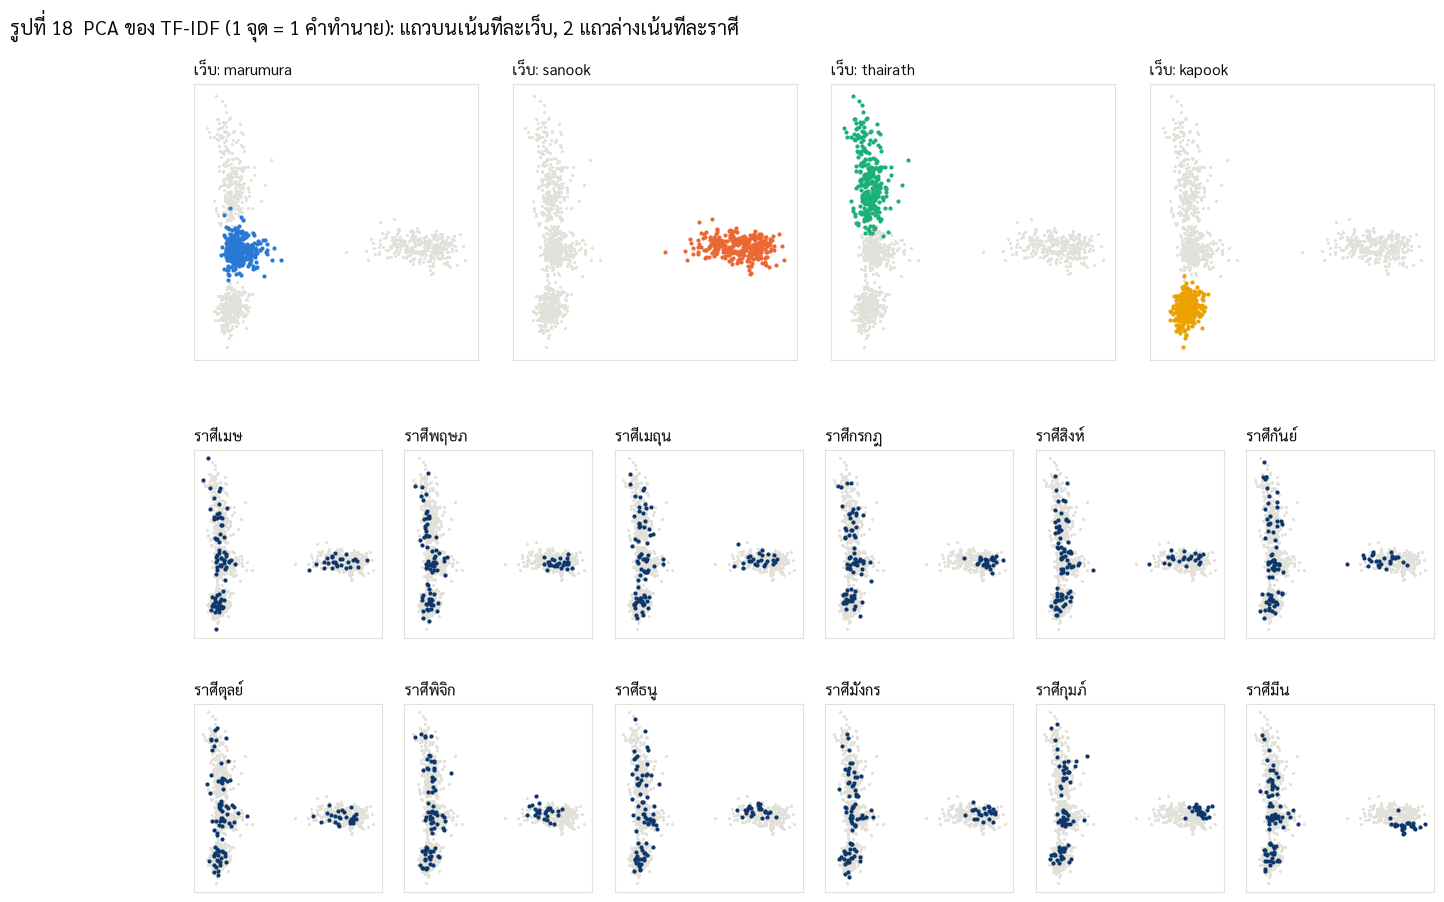

In [7]:
# Figure 18: PCA to 2D, small multiples. Top: one panel per site. Bottom: one panel per sign.
pca = PCA(n_components=2, random_state=42)
xy = pca.fit_transform(X.toarray())
print(f"PCA 2 components explain {pca.explained_variance_ratio_.sum():.1%} of the variance")

fig = plt.figure(figsize=(16, 10.5))
outer = fig.add_gridspec(2, 1, height_ratios=[1.25, 2], hspace=0.25)
top = outer[0].subgridspec(1, 4, wspace=0.12)                 # 4 site panels
bottom = outer[1].subgridspec(2, 6, wspace=0.12, hspace=0.35) # 12 sign panels

def panel(ax, mask, color, title):
    ax.scatter(xy[~mask, 0], xy[~mask, 1], s=5, color="#e1e0d9", linewidths=0)
    ax.scatter(xy[mask, 0], xy[mask, 1], s=9, color=color, linewidths=0)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(True); spine.set_color("#e1e0d9")
    ax.set_title(title, loc="left", fontsize=11)

for c, site in enumerate(SITES):
    panel(fig.add_subplot(top[0, c]), (df["source"] == site).to_numpy(), SITE_COLORS[site], f"เว็บ: {site}")
for k, z in enumerate(SIGNS):
    panel(fig.add_subplot(bottom[k // 6, k % 6]), (df["zodiac"] == z).to_numpy(), "#0d366b", f"ราศี{SIGN_TH[z]}")
fig.suptitle("รูปที่ 18  PCA ของ TF-IDF (1 จุด = 1 คำทำนาย): แถวบนเน้นทีละเว็บ, 2 แถวล่างเน้นทีละราศี",
             x=0.01, ha="left", fontsize=14, y=0.95)
fig.savefig(FIG_DIR / "06_pca_site_vs_sign.png")
plt.show()

**จากรูปที่ 18 พบว่า** (PCA 2 มิติอธิบายความแปรปรวนได้แค่ 7% แต่ก็พอเห็นโครงสร้าง)
- **แถวบน (ทีละเว็บ):** แต่ละเว็บเป็น**ก้อนแยกของตัวเอง**ชัดเจน: sanook อยู่ขวา, thairath อยู่บน, marumura อยู่กลาง, kapook อยู่ล่าง
- **2 แถวล่าง (ทีละราศี):** ทุกราศีมีหน้าตา**เหมือนกันหมด** คือจุดของราศีนั้นกระจายอยู่ใน**ทั้ง 4 ก้อน** ไม่มีราศีไหนมีพื้นที่ของตัวเอง

รูปนี้ใช้ใน presentation ได้ดี เพราะเห็นด้วยตาเลยว่า **เว็บ = ก้อน, ราศี = กระจายทั่ว**

## สรุปผล 06 Clustering

1. **K-means เลือกเองว่า 4 กลุ่มดีที่สุด** (silhouette สูงสุดที่ k = 4) และ 4 กลุ่มนั้นคือ 4 เว็บเกือบสมบูรณ์ (ARI = 0.998)
2. **บังคับให้แบ่ง 12 กลุ่มก็ไม่ได้กลุ่มตามราศี** (ARI กับราศี = 0.028) ทุกกลุ่มอยู่ในเว็บเดียว และกลุ่มที่ตรงกับราศีมาจาก sanook เท่านั้น
3. **ภาพ PCA:** เว็บเป็นก้อนแยกกัน แต่ราศีกระจายไปทุกก้อน

**เชื่อมกับคำถามวิจัย:** เป็นหลักฐานชิ้นที่ 6 (unsupervised เหมือน BERTopic แต่ใช้ TF-IDF + K-means ตาม L9) ว่า**โครงสร้างของข้อความมาจากผู้เขียน ไม่ได้มาจากราศี**

**ข้อจำกัด:** K-means ถือว่ากลุ่มเป็นทรงกลมขนาดใกล้กัน และ silhouette โดยรวมต่ำ (< 0.1) แปลว่ากลุ่มไม่ได้แยกกันห่างมาก แต่ผลตรงกับ BERTopic ที่ใช้วิธีต่างกันโดยสิ้นเชิง

**รูปที่บันทึกไว้:** `outputs/figures/06_elbow_silhouette.png`, `06_crosstab_clusters.png`, `06_pca_site_vs_sign.png`